#SALES REVENUE PREDICTION USING RNN
* Dataset: sales_revenue_dataset.csv
* Target: Revenue(next day revenue predict)
* Model: Recurrent Neural Network (RNN)

#Step 1: Install & Import Libraries

In [ ]:
!pip install -q tensorflow pandas scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings("ignore")
print("✅  Libraries imported!")

✅  Libraries imported!


#STEP 2: UPLOAD & LOAD DATASET:

In [ ]:
from google.colab import files
uploaded = files.upload() # sales revenue_dataset.csv upload file

Saving sales_revenue_dataset (1).csv to sales_revenue_dataset (1) (2).csv


In [ ]:
df = pd.read_csv("/content/sales_revenue_dataset (1).csv")
df.head()

,Date,Store_ID,Product_Category,Units_Sold,Price_Per_Unit,Discount_Percent,Marketing_Spend,Day_of_Week,Is_Holiday,Temperature,Competitor_Price,Revenue
0,2024-01-01,S001,Electronics,160,160.20,4,4358,0,0,33.3,179.05,18265.51
1,2024-01-02,S004,Electronics,35,92.16,7,17559,1,0,31.3,93.85,17689.47
2,2024-01-03,S005,Sports,132,252.14,8,1212,2,0,35.5,226.40,10609.85
3,2024-01-04,S003,Clothing,130,480.75,10,4349,3,0,17.5,422.59,15973.05
4,2024-01-05,S005,Groceries,42,378.38,17,5090,4,0,41.3,364.59,8557.61


In [ ]:
print("shape", df.shape)

shape (200, 12)


In [ ]:
print("\nRevenue Stats:")
print(df["Revenue"].describe().round(2))


Revenue Stats:
count      200.00
mean     12572.57
std       4835.05
min       4334.90
25%       9251.40
50%      11573.90
75%      15628.25
max      27345.73
Name: Revenue, dtype: float64


#STEP 3: PREPROCESSING:

In [ ]:
df.drop("Date", axis=1, inplace=True)

le = LabelEncoder()
for col in ["Store_ID", "Product_Category"]:
  df[col] = le.fit_transform(df[col])

scaler = MinMaxScaler()
scaled = scaler.fit_transform(df)
scaled_df = pd.DataFrame(scaled, columns=df.columns)

print("✅  Preprocessing done")
print(f"Feature: {list(df.columns)}")

✅  Preprocessing done
Feature: ['Store_ID', 'Product_Category', 'Units_Sold', 'Price_Per_Unit', 'Discount_Percent', 'Marketing_Spend', 'Day_of_Week', 'Is_Holiday', 'Temperature', 'Competitor_Price', 'Revenue']


#✅ STEP 4: SEQUENCES:

In [ ]:

def create_sequences(data, target_col, seq_len=10):
  X, y = [], []
  target_idx = list(data.columns).index(target_col)
  vals = data.values
  for i in range(len(vals)- seq_len):
    X.append(vals[i:i+seq_len])
    y.append(vals[i+seq_len][target_idx])

  return np.array(X), np.array(y)

SEQ_LEN =10
X, y = create_sequences(scaled_df, "Revenue", SEQ_LEN)

split =int(len(X)* 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

X_train: (152, 10, 11)
X_test: (38, 10, 11)


#STEP 5: RNN MODEL BUILD & TRAIN:

In [ ]:

model = Sequential([
    SimpleRNN(64, return_sequences=True,
              input_shape=(SEQ_LEN, X.shape[2]),
              activation="tanh"),

    Dropout(0.2),
    SimpleRNN(32, return_sequences=False,
              activation="tanh"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss="mse", metrics=["mae"])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_4 (SimpleRNN)        │ (None, 10, 64)         │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_5 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,513 (33.25 KB)

 Trainable params: 8,513 (33.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)
print("\n✅ Training done!")

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 314ms/step - loss: 0.4190 - mae: 0.5330 - val_loss: 0.0724 - val_mae: 0.2240
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1168 - mae: 0.2740 - val_loss: 0.0670 - val_mae: 0.2274
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0908 - mae: 0.2562 - val_loss: 0.0466 - val_mae: 0.1737
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0911 - mae: 0.2449 - val_loss: 0.0480 - val_mae: 0.1772
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.1004 - mae: 0.2498 - val_loss: 0.0523 - val_mae: 0.1764
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0740 - mae: 0.2228 - val_loss: 0.0501 - val_mae: 0.1829
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0686 - mae: 0.2068 - val_loss: 0.0509 - val_mae: 0.1837
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0761 - mae: 0.2180 - val_loss: 0.0517 - val_mae: 0.1831
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0659 - mae:

# STEP 6: EVALUATE & INVERSE SCALE:

In [ ]:
y_pred_scaled = model.predict(X_test).flatten()

rev_idx = list(df.columns).index("Revenue")
rev_min = scaler.data_min_[rev_idx]
rev_max = scaler.data_max_[rev_idx]

y_test_orig = y_test * (rev_max - rev_min)
y_pred_orig = y_pred_scaled * (rev_max - rev_min)+ rev_min

mae = mean_absolute_error(y_test_orig, y_pred_orig)
rmse = np.sqrt(mean_squared_error(y_test_orig, y_pred_orig))
r2 = r2_score(y_test_orig, y_pred_orig)

print(f"MAE: $ {mae:,.2f}")
print(f"RMSE:$ {rmse:,.2f}")
print(f"R2 : {r2:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step
MAE: $ 6,199.79
RMSE:$ 7,204.71
R2 : -1.2900


#✅ STEP 7: CHARTS - 4 DIFFERENT VISUALIZATION:

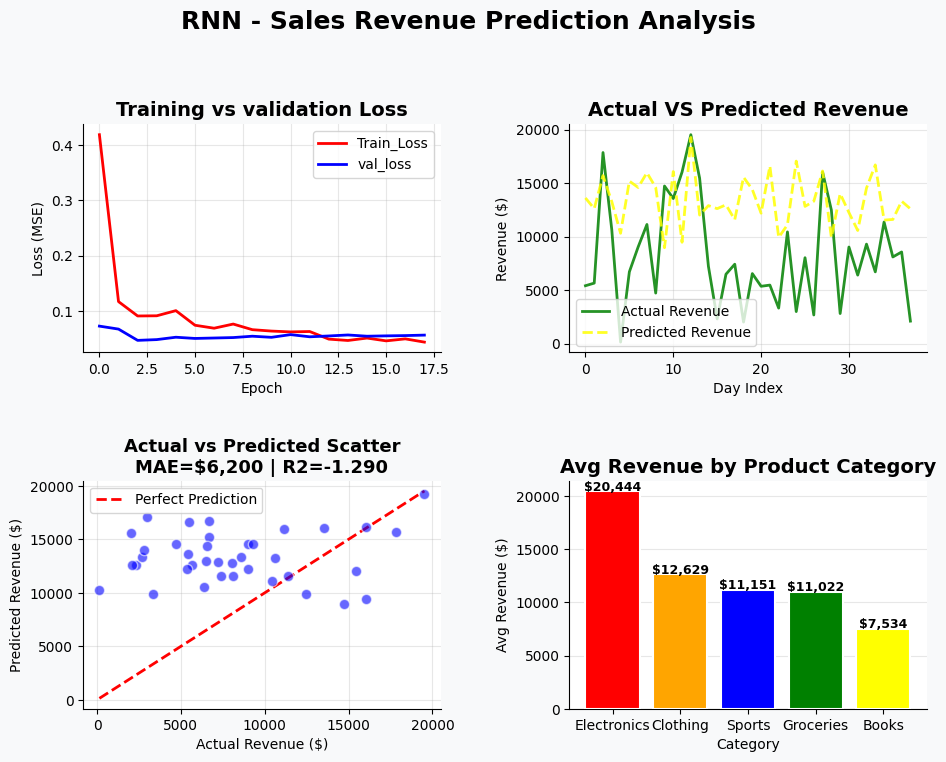

✅ Charts Saved


In [ ]:
fig, axes = plt.subplots(2,2, figsize=(10,8))
fig.suptitle("RNN - Sales Revenue Prediction Analysis", fontsize=18,
fontweight="bold")
fig.patch.set_facecolor("#F8F9FA")

# chart 1: Training Loss Curve
ax1 = axes[0,0]
ax1.plot(history.history["loss"], color="red", lw=2, label="Train_Loss")
ax1.plot(history.history["val_loss"], color="blue", lw=2, label="val_loss")
ax1.set_title("Training vs validation Loss", fontsize=14,fontweight="bold")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss (MSE)")
ax1.legend(); ax1.grid(alpha=0.3)
ax1.set_facecolor("white")
ax1.spines[["top", "right"]].set_visible(False)

#Chart 2: Actual vs Predicted Line
ax2 = axes[0, 1]
ax2.plot(y_test_orig, color="green", lw=2,
         label="Actual Revenue", alpha=0.85)
ax2.plot(y_pred_orig, color="yellow", lw=2,
         label="Predicted Revenue", linestyle="--", alpha=0.85)
ax2.set_title('Actual VS Predicted Revenue', fontsize=14, fontweight="bold")
ax2.set_xlabel("Day Index"); ax2.set_ylabel("Revenue ($)")
ax2.legend(); ax2.grid(alpha=0.3)
ax2.set_facecolor("white")
ax2.spines[["top", "right"]].set_visible(False)

# Chart 3: Scatter - Actual VS Predicted
ax3 = axes[1,0]
ax3.scatter(y_test_orig, y_pred_orig, color="blue", alpha=0.6, s=55, edgecolor="white", zorder=3)
mn = min(y_test_orig.min(), y_pred_orig.min())
mx = max(y_test_orig.max(), y_pred_orig.max())
ax3.plot([mn, mx], [mn, mx], "r--", lw=2, label="Perfect Prediction")
ax3.set_title(f"Actual vs Predicted Scatter\nMAE=${mae:,.0f} | R2={r2:.3f}", fontsize=13, fontweight="bold")
ax3.set_xlabel("Actual Revenue ($)")
ax3.set_ylabel("Predicted Revenue ($)")
ax3.legend(); ax3.grid(alpha=0.3, zorder=0)
ax3.set_facecolor("white")
ax3.spines[["top", "right"]].set_visible(False)

# Chart 4: Category- Wise Revenue Bar
ax4 = axes[1,1]
orig = pd.read_csv("/content/sales_revenue_dataset (1).csv")
# Standardize casing to match actual dataset
orig.columns = [c.lower() for c in orig.columns]
cat_rev = orig.groupby("product_category")["revenue"].mean().sort_values(ascending=False)
colors = ["red","orange", "blue", "green", "yellow"]
bars = ax4.bar(cat_rev.index, cat_rev.values, color=colors[:len(cat_rev)],
               edgecolor="white", linewidth=1.5, zorder=3)

for bar in bars:
  ax4.text(bar.get_x()+bar.get_width()/2., bar.get_height()+100,
           f"${bar.get_height():,.0f}", ha="center",
           fontsize=9, fontweight="bold")

ax4.set_title("Avg Revenue by Product Category",
              fontsize=14, fontweight="bold")
ax4.set_xlabel("Category"); ax4.set_ylabel("Avg Revenue ($)")
ax4.set_facecolor("white"); ax4.grid(axis="y", alpha=0.3, zorder=0)
ax4.spines[["top", "right"]].set_visible(False)

plt.tight_layout(pad=3.0)
plt.savefig("Rnn Sales Charts.png", dpi=150,
            bbox_inches="tight", facecolor="white")
plt.show()
print("✅ Charts Saved")